In [1]:
import os, glob
import pandas as pd
import scanpy as sc
import matplotlib.pyplot as plt

In [ ]:
pth = os.path.join('..', '..')
pth_data = os.path.join(pth, 'data')
pth_in = os.path.join(pth_data, 'cancer', 'invertebrate', 'drosophila')
pth_feat = os.path.join(pth_data, 'features', 'biomart')
# pth_out = os.path.join(pth_data, 'results', 'cancer', 'drosophila')
pth_fig = os.path.join(pth, 'figures', 'invertebrate', 'drosophila')

In [3]:
adata = sc.read_h5ad(os.path.join(pth_in, 'follicle.h5ad'))
adata

AnnData object with n_obs × n_vars = 13429 × 13948
    obs: 'n_genes_by_counts', 'total_counts', 'total_counts_mt', 'pct_counts_mt', 'n_genes', 'n_counts', 'leiden', 'celltype'
    var: 'Accession', 'Chromosome', 'End', 'Start', 'Strand', 'mt', 'n_cells_by_counts', 'mean_counts', 'pct_dropout_by_counts', 'total_counts', 'highly_variable', 'means', 'dispersions', 'dispersions_norm'
    uns: 'celltype_colors', 'diffmap_evals', 'hvg', 'leiden', 'leiden_colors', 'log1p', 'neighbors', 'pca', 'umap'
    obsm: 'X_diffmap', 'X_pca', 'X_umap'
    varm: 'PCs'
    layers: 'ambiguous', 'matrix', 'spliced', 'unspliced'
    obsp: 'connectivities', 'distances'

In [ ]:
fn = os.path.join(pth_data, 'summary.csv')
df_summary = pd.read_csv(fn, index_col = 0)
labels_dict = df_summary.Module.dropna().to_dict()
labels_dict

{'GSE162534': 'Gast', 'GSE229103': 'pSom', 'rRNAModifications': 'Crest'}

In [5]:
feat_fn = sorted(glob.glob(os.path.join(pth_feat, '*.csv')))
get_src = lambda fn: os.path.split(fn)[1].replace('.csv', '')
feat_dict = {get_src(fn) : pd.read_csv(fn) for fn in feat_fn}

# module signatures
g_ref = feat_dict['union'].dmelanogaster.drop_duplicates()
g_ref = g_ref.loc[g_ref.isin(adata.var_names)].copy()
for src, df_src in feat_dict.items():
    if src != 'union':
        print(src)
        g = df_src.dmelanogaster.drop_duplicates()
        g = g.loc[g.isin(adata.var_names)].copy()
        sc.tl.score_genes(adata,
                          gene_list = g,
                          score_name = src,
                          ctrl_as_ref = False,
                          gene_pool = g_ref,
                          random_state = 1234)

GSE162534
GSE229103
rRNAModifications


In [6]:
ix = ['Mitotic',
      'Postmitotic',
      'Main Body',
      'Posterior',
      'Terminal',
      'Stretched',
      'Border',
      'Stalk']

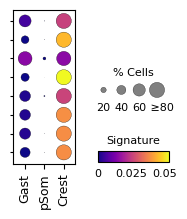

In [10]:
# signatures dotplot
fs1, fs2, src = 9, 8, list(labels_dict.keys())
dp = sc.pl.dotplot(adata, src, 'celltype',
                   categories_order = ix,
                   dot_max = .8, vmin = 0,
                   cmap = 'plasma',
                   figsize = (1.85, 2),
                   return_fig = True,
                   show = False)

dp.style(largest_dot = 120,
         x_padding = .6,
         y_padding = .6)
dp.legend(width = .9)

ax = dp.get_axes()
ax_main = ax['mainplot_ax']
ax_size = ax['size_legend_ax']
cax = ax['color_legend_ax']

ax_size.set_title('% Cells', size = fs2, pad = -9)
ax_size.tick_params('x', size = 0, labelsize = fs2, pad = 2.5)
ax_size.set_xticklabels(['20', '40', '60', '   ≥80'])
cax.set_title('Signature', size = fs2, pad = 5.5)
cax.set_xticks([0, .025, .05], [0, .025, .05])
cax.tick_params('x', size = 0, labelsize = fs2, pad = 5)

pos_main = ax_main.get_position()
pos_size = ax_size.get_position()
pos_color = cax.get_position()

ax_size.set_position([pos_size.x0,
                      pos_size.y0,
                      1.2 * pos_size.width,
                      pos_size.height])

cax.set_position([pos_color.x0,
                  pos_color.y0 + .01 * pos_main.height,
                  1.2 * pos_color.width,
                  pos_color.height])

ax_main.set_xticklabels([labels_dict[lbl.get_text()] for
                         lbl in ax_main.get_xticklabels()],
                        fontsize = fs1)
ax_main.set_yticklabels([])
ax_main.tick_params('y', size = 2.5)

fn = os.path.join(pth_fig, 'signatures.pdf')
plt.savefig(fn, bbox_inches = 'tight')

In [9]:
adata.write(os.path.join(pth_in, 'signatures.h5ad'))

In [ ]:
# # save results
# df = (adata.obs
#       .groupby('celltype', observed = True)
#       [list(labels_dict.keys())].mean())
# df.to_csv(os.path.join(pth_out, 'signatures.csv'))